# ERA5 against five CMIP6 models over Europe

This notebook compares near-surface air temperature from five CMIP6 historical
simulations with the ERA5 reanalysis over Europe (35N to 72N, 10W to 40E) for
1995 to 2014, by season. Both datasets are read anonymously from public cloud
storage: ERA5 from Google's ARCO-ERA5 Zarr store, the models from the Pangeo
CMIP6 catalogue through intake-esm. Nothing needs credentials.

What climval does here:

- puts five models with three different calendars (`noleap`, `proleptic_gregorian`,
  `360_day`) and five different grids on the ERA5 grid and on common months;
- scores all five models in one `climval.compare` call, with the models as an
  extra dimension;
- computes the statistics of a Taylor diagram for the seasonal climatology and
  records every alignment step.

About 560 MB are read from the cloud. The run takes a few minutes on a laptop.

## Setup

In [1]:
import warnings

import dask
import gcsfs
import intake
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import climval

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*Consolidated metadata.*")
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

fs = gcsfs.GCSFileSystem(token="anon")
print("climval", climval.__version__, "| xarray", xr.__version__, "| dask", dask.__version__)

climval 0.2.0 | xarray 2026.9.0 | dask 2026.8.0


In [2]:
PERIOD = ("1995", "2014")
EUROPE = climval.Box(lat=(35, 72), lon=(-10, 40), name="Europe")

## ERA5 from ARCO-ERA5

ARCO-ERA5 has no monthly-mean store. The smallest store with near-surface
temperature is ERA5 conservatively regridded to 1.5 degrees, every 6 hours,
with chunks of 8 time steps (two days) over the whole globe. Reading every
chunk for 20 years would be about 2.2 GB, so this notebook reads one chunk in
six: two consecutive days, with all four analyses (00, 06, 12 and 18 UTC),
every twelve days. Monthly means are then estimated from the sampled days.
The cost of this saving is sampling noise, which is estimated below.

In [3]:
ERA5_STORE = (
    "gcp-public-data-arco-era5/ar/"
    "1959-2022-6h-240x121_equiangular_with_poles_conservative.zarr"
)
era5 = xr.open_zarr("gs://" + ERA5_STORE, storage_options={"token": "anon"}, chunks={})
t2m = era5["2m_temperature"]
print(t2m.dims, t2m.shape, "chunks", t2m.encoding["chunks"], "units", t2m.attrs.get("units"))
print("time", str(era5.time.values[0])[:16], "to", str(era5.time.values[-1])[:16])

('time', 'longitude', 'latitude') (92040, 240, 121) chunks (8, 240, 121) units K
time 1959-01-02T00:00 to 2021-12-31T18:00


In [4]:
EVERY = 6  # read one two-day chunk in six
step = t2m.encoding["chunks"][0]
times = pd.DatetimeIndex(era5.time.values)
i0 = int(np.searchsorted(times, np.datetime64(f"{PERIOD[0]}-01-01")))
i1 = int(np.searchsorted(times, np.datetime64(f"{int(PERIOD[1]) + 1}-01-01")))
blocks = [k for k in range(-(-i0 // step), i1 // step) if k % EVERY == 0]
index = np.concatenate([np.arange(k * step, (k + 1) * step) for k in blocks])

sizes = {f["name"].rsplit("/", 1)[-1]: f["size"] for f in fs.ls(ERA5_STORE + "/2m_temperature", detail=True)}
era5_bytes = sum(sizes[f"{k}.0.0"] for k in blocks)
print(f"{len(blocks)} chunks of {step} time steps, {times[index[0]]} to {times[index[-1]]}")
print(f"ERA5 bytes to read: {era5_bytes / 1e6:.0f} MB")

609 chunks of 8 time steps, 1995-01-05 00:00:00 to 2014-12-28 18:00:00
ERA5 bytes to read: 374 MB


In [5]:
# Only the European part of each global chunk is kept. The reference grid is
# the comparison grid, so a small margin around the box is enough; climval
# cuts the box exactly.
sub = t2m.isel(time=index)
sub = sub.assign_coords(longitude=((sub.longitude + 180) % 360) - 180).sortby("longitude")
sub = sub.sel(latitude=slice(33, 75), longitude=slice(-13, 43)).transpose("time", "latitude", "longitude")
with dask.config.set(scheduler="threads", num_workers=8):
    sub = sub.load()
print(sub.shape, f"{sub.nbytes / 1e6:.0f} MB in memory")

(4872, 28, 37) 20 MB in memory


In [6]:
era5_monthly = sub.resample(time="MS").mean().rename("t2m")
era5_monthly.attrs = {"units": "K", "long_name": "2 m temperature, monthly mean of sampled days"}
days = sub.time.dt.floor("D").to_series().groupby(pd.Grouper(freq="MS")).nunique()
print(f"{era5_monthly.sizes['time']} months; sampled days per month: "
      f"min {days.min()}, max {days.max()}, mean {days.mean():.1f}")

240 months; sampled days per month: min 4, max 6, mean 5.1


### How large is the sampling noise?

Each two-day chunk gives one block mean. For each season and grid point the
standard error of the 20-year seasonal mean is estimated as the standard
deviation of the block means divided by the square root of their number. The
blocks are twelve days apart, so they are treated as independent. The spread
also contains the seasonal cycle within each season, so this is an upper
estimate.

In [7]:
block_means = sub.coarsen(time=step).mean()
by_season = block_means.groupby("time.season")
stderr = by_season.std("time", ddof=1) / np.sqrt(by_season.count("time"))
table = pd.DataFrame(
    {
        "blocks": by_season.count("time").isel(latitude=0, longitude=0).to_series(),
        "median standard error (K)": stderr.median(["latitude", "longitude"]).to_series(),
        "largest standard error (K)": stderr.max(["latitude", "longitude"]).to_series(),
    }
).loc[["DJF", "MAM", "JJA", "SON"]]
table

,blocks,median standard error (K),largest standard error (K)
season,,,
DJF,152,0.271,0.650
MAM,153,0.320,0.686
JJA,153,0.192,0.346
SON,151,0.345,0.617


These errors apply to the seasonal climatology. A single monthly mean rests on
about five sampled days and is far noisier, so this notebook reads the
climatology sample, not month-by-month values.

## CMIP6 models from the Pangeo catalogue

In [8]:
cat = intake.open_esm_datastore("https://storage.googleapis.com/cmip6/pangeo-cmip6.json")
MEMBERS = {
    "CanESM5": "r1i1p1f1",
    "IPSL-CM6A-LR": "r1i1p1f1",
    "MPI-ESM1-2-LR": "r1i1p1f1",
    "NorESM2-LM": "r1i1p1f1",
    "UKESM1-0-LL": "r1i1p1f2",
}
query = cat.search(
    experiment_id="historical",
    table_id="Amon",
    variable_id="tas",
    source_id=list(MEMBERS),
    member_id=sorted(set(MEMBERS.values())),
)
rows = query.df[[MEMBERS[s] == m for s, m in zip(query.df.source_id, query.df.member_id)]]
rows[["source_id", "institution_id", "member_id", "grid_label", "version", "zstore"]]

,source_id,institution_id,member_id,grid_label,version,zstore
0,IPSL-CM6A-LR,IPSL,r1i1p1f1,gr,20180803,gs://cmip6/CMIP6/CMIP/IPSL/IPSL-CM6A-LR/histor...
1,UKESM1-0-LL,MOHC,r1i1p1f2,gn,20190406,gs://cmip6/CMIP6/CMIP/MOHC/UKESM1-0-LL/histori...
2,CanESM5,CCCma,r1i1p1f1,gn,20190429,gs://cmip6/CMIP6/CMIP/CCCma/CanESM5/historical...
3,MPI-ESM1-2-LR,MPI-M,r1i1p1f1,gn,20190710,gs://cmip6/CMIP6/CMIP/MPI-M/MPI-ESM1-2-LR/hist...
4,NorESM2-LM,NCC,r1i1p1f1,gn,20190815,gs://cmip6/CMIP6/CMIP/NCC/NorESM2-LM/historica...


In [9]:
dsets = query.to_dataset_dict(
    xarray_open_kwargs={"consolidated": True, "chunks": {}},
    storage_options={"token": "anon"},
    progressbar=False,
)
models = {}
for ds in dsets.values():
    source = ds.attrs["source_id"]
    models[source] = ds["tas"].sel(member_id=MEMBERS[source]).squeeze(drop=True)
models = dict(sorted(models.items()))


def bytes_for_period(row, period):
    """Bytes of the stored chunks that hold the period (whole global chunks)."""
    store = row.zstore.replace("gs://", "").rstrip("/") + "/tas"
    chunk = xr.open_zarr(row.zstore, storage_options={"token": "anon"})["tas"].encoding["chunks"][0]
    years = models[row.source_id].time.dt.year.values
    idx = np.nonzero((years >= int(period[0])) & (years <= int(period[1])))[0]
    files = {f["name"].rsplit("/", 1)[-1]: f["size"] for f in fs.ls(store, detail=True)}
    return sum(files[f"{c}.0.0"] for c in np.unique(idx // chunk))


info = pd.DataFrame(
    {
        "institution_id": rows.set_index("source_id").institution_id,
        "member_id": rows.set_index("source_id").member_id,
        "grid (lat x lon)": {s: f"{da.sizes['lat']} x {da.sizes['lon']}" for s, da in models.items()},
        "calendar": {s: da.time.dt.calendar for s, da in models.items()},
        "MB to read": {r.source_id: bytes_for_period(r, PERIOD) / 1e6 for r in rows.itertuples()},
    }
).sort_index()
print(f"CMIP6 bytes to read: {info['MB to read'].sum():.0f} MB; "
      f"total with ERA5: {(info['MB to read'].sum() + era5_bytes / 1e6):.0f} MB")
info.round(1)

CMIP6 bytes to read: 185 MB; total with ERA5: 559 MB


,institution_id,member_id,grid (lat x lon),calendar,MB to read
CanESM5,CCCma,r1i1p1f1,64 x 128,noleap,16.4
IPSL-CM6A-LR,IPSL,r1i1p1f1,143 x 144,proleptic_gregorian,40.7
MPI-ESM1-2-LR,MPI-M,r1i1p1f1,96 x 192,proleptic_gregorian,39.7
NorESM2-LM,NCC,r1i1p1f1,96 x 144,noleap,34.2
UKESM1-0-LL,MOHC,r1i1p1f2,144 x 192,360_day,53.9


## Align each model with ERA5

`climval.align` runs the alignment steps without computing a metric. Each
model is cut to the box with a one-cell margin, matched to the ERA5 months by
year and month (so a `360_day` or `noleap` month meets the same calendar
month of ERA5), interpolated bilinearly onto the 1.5 degree ERA5 grid and
checked for units. `target="reference"` makes the ERA5 grid the comparison
grid.

In [10]:
aligned = {}
time_steps = {}
for source, tas in models.items():
    pair = climval.align(era5_monthly, tas, region=EUROPE, period=PERIOD, target="reference")
    with dask.config.set(scheduler="threads", num_workers=4):
        aligned[source] = pair.candidate.load()
    time_steps[source] = next(s for s in pair.steps if s["step"] == "time")
reference = pair.reference

pd.DataFrame(
    {
        s: {
            "calendars": f"{t['calendars']['reference']} / {t['calendars']['candidate']}",
            "matched months": t["matched_periods"],
            "range": " to ".join(r[:7] for r in t["range"]),
        }
        for s, t in time_steps.items()
    }
).T

,calendars,matched months,range
CanESM5,proleptic_gregorian / noleap,240,1995-01 to 2014-12
IPSL-CM6A-LR,proleptic_gregorian / proleptic_gregorian,240,1995-01 to 2014-12
MPI-ESM1-2-LR,proleptic_gregorian / proleptic_gregorian,240,1995-01 to 2014-12
NorESM2-LM,proleptic_gregorian / noleap,240,1995-01 to 2014-12
UKESM1-0-LL,proleptic_gregorian / 360_day,240,1995-01 to 2014-12


In [11]:
for line in climval.result.describe_steps(pair.steps):
    print(line)

inputs: reference_variable=t2m, candidate_variable=tas
coordinates: reference={...}, candidate={"grid": "rectilinear", "detected": {"lat": "lat", "lon": "lon", "time": "time"}, "changes": []}
target_grid: target=reference, regridded=["candidate"]
longitude: frame=[-180.0, 180.0], reference=-180..180 unchanged, candidate=0..360 re-expressed in frame
region: region={"type": "box", "name": "Europe", "lat": [35, 72], "lon": [-10, 40], "crosses_antimeridian": false}, reference_points={"lat": 25, "lon": 33}, candidate_padded=global longitude: one wrapped column added at each end, candidate_points={"lat": 32, "lon": 28}
time: calendars={"reference": "proleptic_gregorian", "candidate": "360_day"}, period=["1995", "2014"], native_frequency={"reference": "monthly", "candidate": "monthly"}, frequency=monthly, matched_periods=240, unmatched_dropped={"reference": 0, "candidate": 0}, method=periods matched by calendar labels (year-month), not by timestamp, range=["1995-01-01T00:00:00.000000000", "20

## Five models in one call

The aligned models are stacked along a new dimension `model`. climval keeps
extra dimensions, so one `compare` call gives one value per model, season and
metric. The `time` sample adds per-grid-point maps.

In [12]:
stack = xr.concat(list(aligned.values()), dim=pd.Index(list(aligned), name="model"))
result = climval.compare(
    reference,
    stack,
    by="season",
    names=("ERA5", "CMIP6 historical"),
    samples=("space_time", "climatology", "time"),
)
result

Sample,Group,model,Metric,Value,Units
space_time,all,CanESM5,rmse,2.8634,K
space_time,all,IPSL-CM6A-LR,rmse,3.1083,K
space_time,all,MPI-ESM1-2-LR,rmse,3.0968,K
space_time,all,NorESM2-LM,rmse,3.2909,K
space_time,all,UKESM1-0-LL,rmse,3.5384,K
space_time,DJF,CanESM5,rmse,3.6446,K
space_time,DJF,IPSL-CM6A-LR,rmse,4.1258,K
space_time,DJF,MPI-ESM1-2-LR,rmse,3.9056,K
space_time,DJF,NorESM2-LM,rmse,4.1243,K
space_time,DJF,UKESM1-0-LL,rmse,5.0872,K


## Taylor statistics of the seasonal climatology

The `climatology` sample compares the 20-year mean fields of each season over
space, with cos(latitude) weights. `pearson_r` is the pattern correlation,
`std_ratio` the ratio of spatial standard deviations (model over ERA5),
`crmse` the centred root mean square difference and `mean_bias` the
area-weighted mean difference, model minus ERA5.

In [13]:
values = result.to_dataframe()
clim = values[values["sample"] == "climatology"].pivot_table(
    index=["model", "group"], columns="metric", values="value"
)
seasons = ["DJF", "MAM", "JJA", "SON", "all"]
taylor = clim[["mean_bias", "rmse", "crmse", "pearson_r", "std_ratio"]].reindex(
    pd.MultiIndex.from_product([list(aligned), seasons], names=["model", "group"])
)
taylor.round(3)

metric               mean_bias   rmse  crmse  pearson_r  std_ratio
model         group                                               
CanESM5       DJF        0.602  1.704  1.594      0.970      1.006
              MAM        0.011  1.148  1.148      0.971      0.950
              JJA        0.445  1.273  1.192      0.980      1.103
              SON        0.337  1.326  1.283      0.972      1.020
              all        0.349  1.182  1.129      0.975      1.022
IPSL-CM6A-LR  DJF       -0.854  1.661  1.424      0.982      1.093
              MAM       -1.088  1.490  1.018      0.977      0.976
              JJA        0.778  1.578  1.373      0.965      0.897
              SON        0.426  1.050  0.960      0.984      0.996
              all       -0.184  0.976  0.959      0.982      0.998
MPI-ESM1-2-LR DJF       -0.154  1.483  1.475      0.976      1.033
              MAM       -0.672  1.360  1.182      0.969      0.983
              JJA       -0.168  1.453  1.444      0.962      1.045
              SON       -0.022  1.303  1.303      0.975      1.070
              all       -0.254  1.174  1.146      0.976      1.040
NorESM2-LM    DJF        1.615  2.521  1.936      0.955      0.978
              MAM        0.644  1.559  1.420      0.978      1.191
              JJA        0.242  1.763  1.747      0.972      1.224
              SON        0.662  1.723  1.591      0.963      1.084
              all        0.791  1.687  1.490      0.972      1.152
UKESM1-0-LL   DJF       -1.966  2.942  2.189      0.981      1.253
              MAM       -1.491  1.865  1.120      0.975      1.052
              JJA       -0.599  1.617  1.502      0.972      1.149
              SON       -0.458  1.125  1.028      0.986      1.081
              all       -1.129  1.667  1.227      0.983      1.143

In [14]:
annual = taylor.xs("all", level="group")
print("Annual-mean climatology (group 'all'):")
print(f"  pattern correlation from {annual.pearson_r.min():.3f} ({annual.pearson_r.idxmin()}) "
      f"to {annual.pearson_r.max():.3f} ({annual.pearson_r.idxmax()})")
print(f"  mean bias from {annual.mean_bias.min():+.2f} K ({annual.mean_bias.idxmin()}) "
      f"to {annual.mean_bias.max():+.2f} K ({annual.mean_bias.idxmax()})")
print(f"  centred RMS difference from {annual.crmse.min():.2f} K ({annual.crmse.idxmin()}) "
      f"to {annual.crmse.max():.2f} K ({annual.crmse.idxmax()})")
seasonal = taylor.drop(index="all", level="group")
worst = seasonal.mean_bias.abs().idxmax()
print(f"Largest seasonal bias in size: {worst[0]} in {worst[1]}, "
      f"{seasonal.mean_bias.loc[worst]:+.2f} K")
print(f"Lowest seasonal pattern correlation: {seasonal.pearson_r.min():.3f} "
      f"({', '.join(seasonal.pearson_r.idxmin())})")

Annual-mean climatology (group 'all'):
  pattern correlation from 0.972 (NorESM2-LM) to 0.983 (UKESM1-0-LL)
  mean bias from -1.13 K (UKESM1-0-LL) to +0.79 K (NorESM2-LM)
  centred RMS difference from 0.96 K (IPSL-CM6A-LR) to 1.49 K (NorESM2-LM)
Largest seasonal bias in size: UKESM1-0-LL in DJF, -1.97 K
Lowest seasonal pattern correlation: 0.955 (NorESM2-LM, DJF)


### Taylor diagrams

The angle is the pattern correlation, the radius the standard deviation
ratio, and the distance to the ERA5 point at radius 1 the centred RMS
difference in units of the ERA5 spatial standard deviation (Taylor 2001).

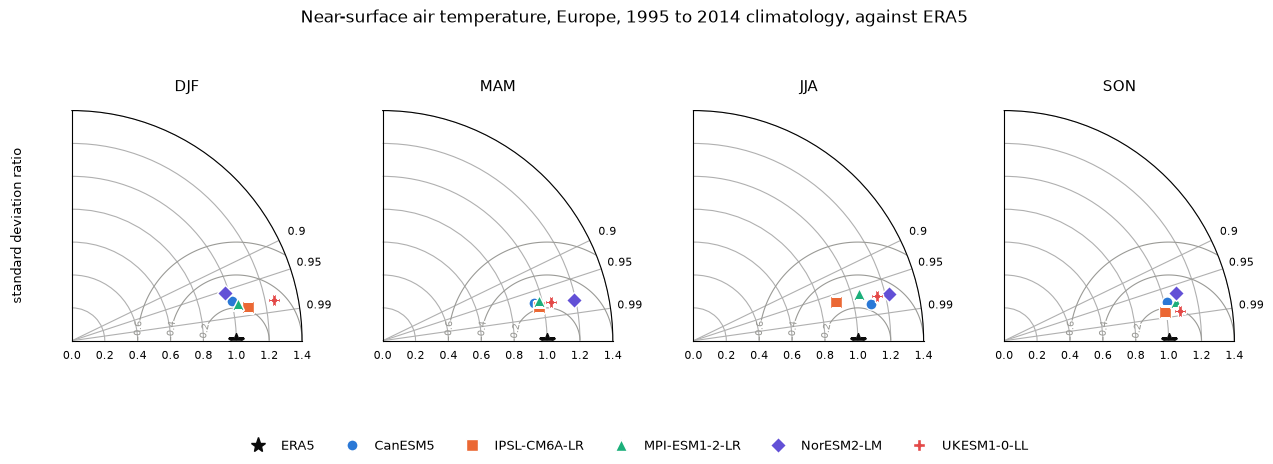

In [15]:
COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e34948"]
MARKERS = ["o", "s", "^", "D", "P"]

fig, axes = plt.subplots(1, 4, figsize=(15, 4.6), subplot_kw={"projection": "polar"})
rmax = 1.4
for ax, season in zip(axes, ["DJF", "MAM", "JJA", "SON"]):
    ax.set_thetamin(0)
    ax.set_thetamax(90)
    ax.set_rlim(0, rmax)
    r_ticks = np.array([0.9, 0.95, 0.99])
    ax.set_thetagrids(np.degrees(np.arccos(r_ticks)), [f"{r:g}" for r in r_ticks], fontsize=8)
    ax.tick_params(axis="y", labelsize=8)
    # centred RMS difference contours around the reference point
    th, rr = np.meshgrid(np.linspace(0, np.pi / 2, 200), np.linspace(0, rmax, 200))
    crms = np.sqrt(1 + rr**2 - 2 * rr * np.cos(th))
    cs = ax.contour(th, rr, crms, levels=[0.2, 0.4, 0.6], colors="#9a9a96", linewidths=0.8)
    ax.clabel(cs, fontsize=7, fmt="%.1f")
    ax.plot(0, 1, marker="*", markersize=12, color="#0b0b0b", zorder=5)
    for i, model in enumerate(aligned):
        row = taylor.loc[(model, season)]
        ax.plot(np.arccos(row.pearson_r), row.std_ratio, marker=MARKERS[i], markersize=8,
                color=COLOURS[i], markeredgecolor="white", markeredgewidth=1.0, linestyle="none",
                label=model, zorder=6)
    ax.set_title(season, pad=14, fontsize=11)
axes[0].set_ylabel("standard deviation ratio", labelpad=28, fontsize=9)
handles, labels = axes[0].get_legend_handles_labels()
handles.insert(0, plt.Line2D([], [], marker="*", color="#0b0b0b", linestyle="none", markersize=11))
labels.insert(0, "ERA5")
fig.legend(handles, labels, loc="lower center", ncol=6, frameon=False, fontsize=9)
fig.suptitle("Near-surface air temperature, Europe, 1995 to 2014 climatology, against ERA5",
             fontsize=12)
fig.subplots_adjust(bottom=0.2, top=0.82, wspace=0.35)
plt.show()

## Where the seasonal biases are

The `time` sample holds per-grid-point statistics over the time steps of each
group. Its `mean_bias` is the 20-year seasonal mean difference at each point.
The grey line is the ERA5 land-sea boundary on the same 1.5 degree grid.

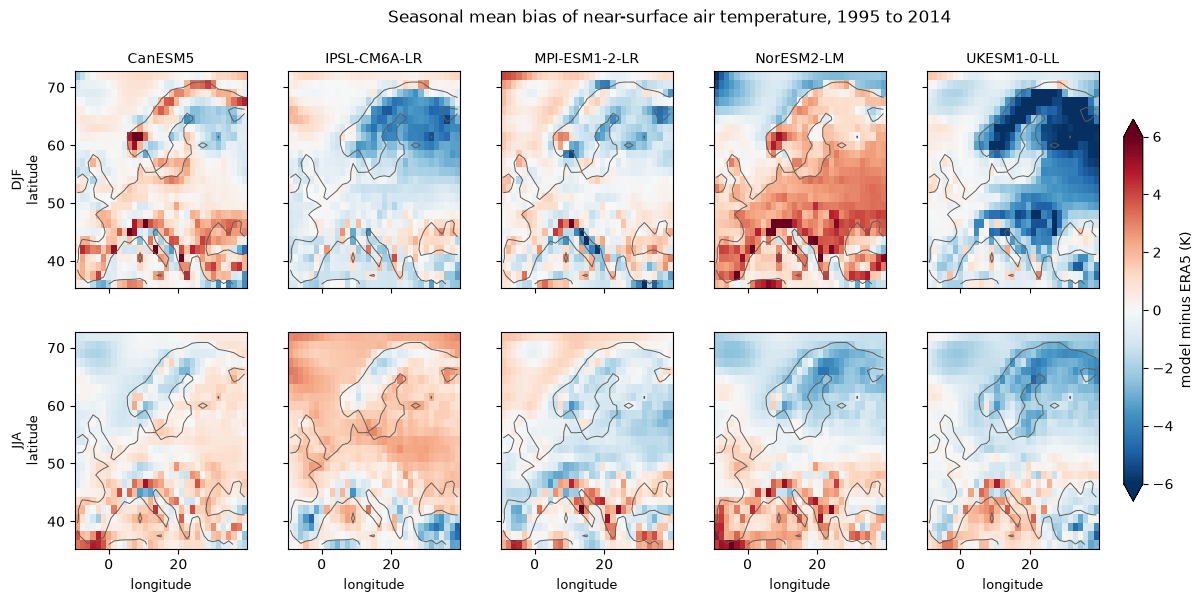

In [16]:
maps = result.field("time")["mean_bias"]
lsm = era5["land_sea_mask"]
if "time" in lsm.dims:
    lsm = lsm.isel(time=0)
lsm = lsm.assign_coords(longitude=((lsm.longitude + 180) % 360) - 180).sortby("longitude")
lsm = lsm.sel(latitude=slice(35, 72), longitude=slice(-10, 40)).load().transpose("latitude", "longitude")

limit = 6.0
fig, axes = plt.subplots(2, 5, figsize=(16, 6.2), sharex=True, sharey=True)
for row, season in enumerate(["DJF", "JJA"]):
    for col, model in enumerate(aligned):
        ax = axes[row, col]
        field = maps.sel(group=season, model=model)
        mesh = ax.pcolormesh(field.lon, field.lat, field.transpose("lat", "lon"),
                             cmap="RdBu_r", vmin=-limit, vmax=limit, shading="nearest")
        ax.contour(lsm.longitude, lsm.latitude, lsm, levels=[0.5], colors="#5f5e5a", linewidths=0.7)
        ax.set_aspect(1 / np.cos(np.deg2rad(53)))
        if row == 0:
            ax.set_title(model, fontsize=10)
        if col == 0:
            ax.set_ylabel(f"{season}\nlatitude", fontsize=9)
        if row == 1:
            ax.set_xlabel("longitude", fontsize=9)
cbar = fig.colorbar(mesh, ax=axes, shrink=0.8, pad=0.02, extend="both")
cbar.set_label("model minus ERA5 (K)")
fig.suptitle("Seasonal mean bias of near-surface air temperature, 1995 to 2014", fontsize=12)
plt.show()

In [17]:
over = (np.abs(maps.sel(group=["DJF", "JJA"])) > limit).sum(["lat", "lon"])
print("Grid points beyond the colour scale of +-6 K (out of "
      f"{maps.sizes['lat'] * maps.sizes['lon']}):")
over.to_pandas()

Grid points beyond the colour scale of +-6 K (out of 825):


model,CanESM5,IPSL-CM6A-LR,MPI-ESM1-2-LR,NorESM2-LM,UKESM1-0-LL
group,,,,,
DJF,5,0,3,10,61
JJA,0,0,1,0,0


The maps have two kinds of structure: large areas of one sign, and
small-scale speckle along mountains and coasts, where a coarse model grid
and the 1.5 degree ERA5 grid resolve the terrain and the coastline
differently. To put a number on the large-scale part, the next cell averages
the seasonal bias maps (cos-latitude weighted) over two sub-boxes of the
region: the north-east (55N to 72N, 10E to 40E) and the south (35N to 48N).

In [18]:
weights = np.cos(np.deg2rad(maps.lat))
parts = {
    "north-east": maps.sel(lat=slice(55, 72), lon=slice(10, 40)),
    "south": maps.sel(lat=slice(35, 48)),
}
sub_means = pd.DataFrame(
    {
        (name, season): part.sel(group=season).weighted(weights).mean(["lat", "lon"]).to_pandas()
        for name, part in parts.items()
        for season in ["DJF", "JJA"]
    }
)
for (name, season), column in sub_means.items():
    cold = ", ".join(column[column < -1].index) or "none"
    warm = ", ".join(column[column > 1].index) or "none"
    print(f"{season} {name}: colder than ERA5 by more than 1 K: {cold}; warmer by more than 1 K: {warm}")
sub_means.round(2)

DJF north-east: colder than ERA5 by more than 1 K: IPSL-CM6A-LR, MPI-ESM1-2-LR, UKESM1-0-LL; warmer by more than 1 K: NorESM2-LM
JJA north-east: colder than ERA5 by more than 1 K: NorESM2-LM, UKESM1-0-LL; warmer by more than 1 K: IPSL-CM6A-LR
DJF south: colder than ERA5 by more than 1 K: UKESM1-0-LL; warmer by more than 1 K: CanESM5, NorESM2-LM
JJA south: colder than ERA5 by more than 1 K: none; warmer by more than 1 K: NorESM2-LM


north-east       south      
                     DJF   JJA   DJF   JJA
model                                     
CanESM5             0.04  0.14  1.03  0.94
IPSL-CM6A-LR       -2.35  1.23 -0.44 -0.03
MPI-ESM1-2-LR      -1.14 -0.85 -0.01  0.25
NorESM2-LM          1.05 -1.74  2.22  1.47
UKESM1-0-LL        -4.04 -2.20 -1.40  0.20

## Month by month

The `space_time` sample compares every month at every grid point. A free
running historical simulation is not synchronised with the observed weather,
so these numbers include internal variability and, here, the sampling noise
of the ERA5 monthly means. They are larger than the climatology numbers and
should not be read as model error alone.

In [19]:
st = values[(values["sample"] == "space_time") & (values["group"] == "all")]
st.pivot_table(index="model", columns="metric", values="value")[["mean_bias", "rmse", "pearson_r"]].round(3)

metric,mean_bias,rmse,pearson_r
model,,,
CanESM5,0.349,2.863,0.943
IPSL-CM6A-LR,-0.184,3.108,0.937
MPI-ESM1-2-LR,-0.254,3.097,0.934
NorESM2-LM,0.791,3.291,0.928
UKESM1-0-LL,-1.129,3.538,0.935


## Provenance and reports

The result records the inputs, every alignment step and the software
versions. It exports to JSON, HTML and Markdown.

In [20]:
prov = result.provenance
print("alignment options of each model:", pair.options)
print("options of the comparison of the stacked models:", prov["options"])
print("created", prov["created"])
env = prov["environment"]
print("climval", env["climval"], "| python", env["python"], "|",
      ", ".join(f"{k} {env['libraries'][k]}" for k in ("xarray", "numpy", "dask", "zarr") if k in env["libraries"]))

alignment options of each model: {'regrid': 'bilinear', 'target': 'reference', 'time': 'intersect', 'freq': None, 'period': ['1995', '2014'], 'units': 'convert', 'weights': 'area', 'region': {'type': 'box', 'name': 'Europe', 'lat': [35, 72], 'lon': [-10, 40], 'crosses_antimeridian': False}}
options of the comparison of the stacked models: {'regrid': 'bilinear', 'target': 'reference', 'time': 'intersect', 'freq': None, 'period': None, 'units': 'convert', 'weights': 'area', 'region': None, 'by': 'season', 'samples': ['space_time', 'climatology', 'time'], 'metrics': ['rmse', 'mae', 'mean_bias', 'nrmse', 'pearson_r', 'taylor_skill_score', 'percentile_bias_p95', 'percentile_bias_p5', 'crmse', 'std_ratio', 'kge']}
created 2026-10-29T23:49:07+00:00
climval 0.2.0 | python 3.12.10 | xarray 2026.9.0, numpy 2.5.4, dask 2026.8.0, zarr 3.4.2


In [21]:
result.export("output/era5_cmip6_europe.html")
result.export("output/era5_cmip6_europe.json")
print("written to output/")

written to output/

## What the numbers show

- All five models reproduce the large-scale pattern of the seasonal
  climatology closely: the pattern correlations printed above are high in
  every season. A temperature field over Europe is dominated by the
  north-south gradient and the land-sea contrast, so a high pattern
  correlation of this kind says little about regional detail.
- The models differ more in their mean bias and their centred RMS
  difference. The summary after the table names the extremes of each.
- The bias maps show large areas of one sign, quantified for two sub-boxes
  in the table above, and small-scale speckle near mountains and coasts.
  This comparison does not adjust for the different orography of the
  grids, so the speckle should not be read as model error alone.
- Month by month (`space_time`), the RMS differences are larger than for
  the climatology, as expected for free-running simulations.

Limits of this comparison: one member per model; one reanalysis; ERA5
monthly means estimated from one sampled two-day block in six (standard
errors above); bilinear regridding onto 1.5 degrees; no orography
adjustment; a box that includes sea points. The numbers describe these five
simulations against ERA5 over this box and period, nothing more.

## Data and licences

**ERA5**: Hersbach et al. (2020), https://doi.org/10.1002/qj.3803, read from
ARCO-ERA5 (Carver and Merose 2023, https://github.com/google-research/arco-era5)
in Google Cloud public datasets. ERA5 is available under the Licence to Use
Copernicus Products. Contains modified Copernicus Climate Change Service
information 2026. Neither the European Commission nor ECMWF is responsible
for any use that may be made of the Copernicus information or data it
contains.

**CMIP6**: Eyring et al. (2016), https://doi.org/10.5194/gmd-9-1937-2016,
read from the Pangeo CMIP6 collection on Google Cloud
(https://pangeo-data.github.io/pangeo-cmip6-cloud/). The model output is
licensed under CC BY 4.0. The table below lists the models, their institutions
and the licence text each dataset carries. We acknowledge the World Climate
Research Programme, which, through its Working Group on Coupled Modelling,
coordinated and promoted CMIP6, the climate modelling groups for producing
and making available their model output, the Earth System Grid Federation
(ESGF) for archiving the data and providing access, and the multiple funding
agencies who support CMIP6 and ESGF.

In [22]:
pd.DataFrame(
    {
        s: {
            "institution_id": ds.attrs.get("institution_id"),
            "institution": ds.attrs.get("institution"),
            "licence": ds.attrs.get("license"),
        }
        for s, ds in sorted((d.attrs["source_id"], d) for d in dsets.values())
    }
).T.style.set_properties(**{"white-space": "normal", "text-align": "left"})

,institution_id,institution,licence
CanESM5,CCCma,"Canadian Centre for Climate Modelling and Analysis, Environment and Climate Change Canada, Victoria, BC V8P 5C2, Canada","CMIP6 model data produced by The Government of Canada (Canadian Centre for Climate Modelling and Analysis, Environment and Climate Change Canada) is licensed under a Creative Commons Attribution ShareAlike 4.0 International License (https://creativecommons.org/licenses). Consult https://pcmdi.llnl.gov/CMIP6/TermsOfUse for terms of use governing CMIP6 output, including citation requirements and proper acknowledgment. Further information about this data, including some limitations, can be found via the further_info_url (recorded as a global attribute in this file) and at https:///pcmdi.llnl.gov/. The data producers and data providers make no warranty, either express or implied, including, but not limited to, warranties of merchantability and fitness for a particular purpose. All liabilities arising from the supply of the information (including any liability arising in negligence) are excluded to the fullest extent permitted by law."
IPSL-CM6A-LR,IPSL,"Institut Pierre Simon Laplace, Paris 75252, France","CMIP6 model data produced by IPSL is licensed under a Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International License (https://creativecommons.org/licenses). Consult https://pcmdi.llnl.gov/CMIP6/TermsOfUse for terms of use governing CMIP6 output, including citation requirements and proper acknowledgment. Further information about this data, including some limitations, can be found via the further_info_url (recorded as a global attribute in this file) and at https://cmc.ipsl.fr/. The data producers and data providers make no warranty, either express or implied, including, but not limited to, warranties of merchantability and fitness for a particular purpose. All liabilities arising from the supply of the information (including any liability arising in negligence) are excluded to the fullest extent permitted by law."
MPI-ESM1-2-LR,MPI-M,"Max Planck Institute for Meteorology, Hamburg 20146, Germany","CMIP6 model data produced by MPI-M is licensed under a Creative Commons Attribution ShareAlike 4.0 International License (https://creativecommons.org/licenses). Consult https://pcmdi.llnl.gov/CMIP6/TermsOfUse for terms of use governing CMIP6 output, including citation requirements and proper acknowledgment. Further information about this data, including some limitations, can be found via the further_info_url (recorded as a global attribute in this file) and. The data producers and data providers make no warranty, either express or implied, including, but not limited to, warranties of merchantability and fitness for a particular purpose. All liabilities arising from the supply of the information (including any liability arising in negligence) are excluded to the fullest extent permitted by law."
NorESM2-LM,NCC,"NorESM Climate modeling Consortium consisting of CICERO (Center for International Climate and Environmental Research, Oslo 0349), MET-Norway (Norwegian Meteorological Institute, Oslo 0313), NERSC (Nansen Environmental and Remote Sensing Center, Bergen 5006), NILU (Norwegian Institute for Air Research, Kjeller 2027), UiB (University of Bergen, Bergen 5007), UiO (University of Oslo, Oslo 0313) and UNI (Uni Research, Bergen 5008), Norway. Mailing address: NCC, c/o MET-Norway, Henrik Mohns plass 1, Oslo 0313, Norway","CMIP6 model data produced by NCC is licensed under a Creative Commons Attribution ShareAlike 4.0 International License (https://creativecommons.org/licenses). Consult https://pcmdi.llnl.gov/CMIP6/TermsOfUse for terms of use governing CMIP6 output, including citation requirements and proper acknowledgment. Further information about this data, including some limitations, can be found via the further_info_url (recorded as a global attribute in this file) and at https:///pcmdi.llnl.gov/. The data producers and data providers make no warran